# TBMM 28th Term Speech Level Analysis

Bu notebook `donem28_konusmaci_bazli.csv` verisi üzerinde PySpark ile kapsamlı bir analiz yapar.




## Imports & Starting Spark

In [ ]:
!pip install -q pyspark

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("TBMM_Analysis") \
    .getOrCreate()

print("Spark Version:", spark.version)

Spark Version: 4.0.2


## EDA

In [ ]:

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("TBMM_Analiz") \
    .getOrCreate()

df = spark.read.csv("/content/drive/MyDrive/tbmm_raw_tutanaklar/donem28_konusmaci_bazli.csv",
                    header=True,
                    inferSchema=True,
                    multiLine=True,
                    escape='"')

print("Toplam satır:", df.count())
print("\nŞema:")
df.printSchema()
print("\nİlk 5 satır (temel sütunlar):")
df.select("session_id", "date", "konusmaci_ad_soyad",
          "konusmaci_parti", "konusmaci_sehir",
          "konusmaci_tip", "kelime_sayisi").show(5, truncate=30)

print("\nParti dağılımı:")
df.groupBy("konusmaci_parti") \
  .count() \
  .orderBy("count", ascending=False).show()

print("\nKonuşmacı tip dağılımı:")
df.groupBy("konusmaci_tip") \
  .count() \
  .orderBy("count", ascending=False).show()

Toplam satır: 196442

Şema:
root
 |-- session_id: string (nullable = true)
 |-- donem: integer (nullable = true)
 |-- yasama_yili: integer (nullable = true)
 |-- birlesim_no: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- list_page_url: string (nullable = true)
 |-- ham_page_url: string (nullable = true)
 |-- ozet_page_url: string (nullable = true)
 |-- ham_html_url: string (nullable = true)
 |-- konusmaci_raw: string (nullable = true)
 |-- konusmaci_ad_soyad: string (nullable = true)
 |-- konusma_text: string (nullable = true)
 |-- konusma_sirasi: integer (nullable = true)
 |-- konusma_uzunlugu: integer (nullable = true)
 |-- kelime_sayisi: integer (nullable = true)
 |-- konusmaci_parti: string (nullable = true)
 |-- konusmaci_sehir: string (nullable = true)
 |-- konusmaci_tip: string (nullable = true)


İlk 5 satır (temel sütunlar):
+----------+----------+------------------+---------------+---------------+-------------+-------------+
|session_id|      date|konusmaci

In [ ]:
df.show(5, truncate=False)

+----------+-----+-----------+-----------+----------+--------------------------------------------------------------------------------+----------------------------------------------------------------------------------+-----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+---------------------+------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
print("Toplam konuşma sayısı:", df.count())
print("Sütunlar:")
print(df.columns)

Toplam konuşma sayısı: 196442
Sütunlar:
['session_id', 'donem', 'yasama_yili', 'birlesim_no', 'date', 'list_page_url', 'ham_page_url', 'ozet_page_url', 'ham_html_url', 'konusmaci_raw', 'konusmaci_ad_soyad', 'konusma_text', 'konusma_sirasi', 'konusma_uzunlugu', 'kelime_sayisi', 'konusmaci_parti', 'konusmaci_sehir', 'konusmaci_tip']


## ANALYSIS 1: Number of utterances by party and total word count

In [ ]:
# Sadece milletvekili konuşmalarını filtrele + parti isimlerini standartlaştır
from pyspark.sql.functions import col, when, sum as spark_sum, count as spark_count, round as spark_round

# Sadece milletvekili konuşmaları (başkan, bakan vb. hariç)
mv_df = df.filter(col("konusmaci_tip") == "milletvekili") \
          .filter(col("konusmaci_parti").isNotNull())

# Parti isimlerini kısalt
mv_df = mv_df.withColumn("parti",
    when(col("konusmaci_parti") == "AK PARTİ", "AKP")
    .when(col("konusmaci_parti") == "DEM PARTİ", "DEM")
    .when(col("konusmaci_parti") == "HEDEP / DEM PARTİ", "DEM")
    .when(col("konusmaci_parti") == "YEŞİL SOL PARTİ", "DEM")
    .when(col("konusmaci_parti") == "İYİ PARTİ", "İYİ PARTİ")
    .when(col("konusmaci_parti") == "YENİ YOL PARTİSİ", "YENİ YOL")
    .when(col("konusmaci_parti") == "SAADET PARTİSİ", "SAADET")
    .when(col("konusmaci_parti") == "YENİDEN REFAH", "YENİDEN REFAH")
    .otherwise(col("konusmaci_parti"))
)

# --- ANALİZ 1: Parti bazlı konuşma sayısı ve toplam kelime ---
print("=" * 55)
print("ANALİZ 1: Parti Bazlı Konuşma İstatistikleri")
print("=" * 55)

parti_stats = mv_df.groupBy("parti") \
    .agg(
        spark_count("*").alias("konusma_sayisi"),
        spark_sum("kelime_sayisi").alias("toplam_kelime"),
        spark_round(F.avg("kelime_sayisi"), 1).alias("ort_kelime")
    ) \
    .orderBy("konusma_sayisi", ascending=False)

parti_stats.show(truncate=False)

ANALİZ 1: Parti Bazlı Konuşma İstatistikleri
+-------------+--------------+-------------+----------+
|parti        |konusma_sayisi|toplam_kelime|ort_kelime|
+-------------+--------------+-------------+----------+
|CHP          |36711         |2225464      |60.6      |
|AKP          |34784         |1464891      |42.1      |
|DEM          |20111         |1292541      |64.3      |
|İYİ PARTİ    |10002         |911307       |91.1      |
|YENİ YOL     |7601          |819486       |107.8     |
|MHP          |2560          |283640       |110.8     |
|TİP          |360           |18696        |51.9      |
|YENİDEN REFAH|267           |37707        |141.2     |
|EMEP         |229           |20844        |91.0      |
|SAADET       |190           |18323        |96.4      |
|DSP          |184           |28459        |154.7     |
|BAĞIMSIZ     |171           |15324        |89.6      |
|HÜDA PAR     |125           |15303        |122.4     |
|DP           |93            |21244        |228.4     |
|DB

## ANALYSIS 2: Party Speaking Trends by Parliamentary Year

In [ ]:
# Yasama yılı bazlı parti aktivite trendi
print("=" * 55)
print("ANALİZ 2: Yasama Yılına Göre Parti Konuşma Trendi")
print("=" * 55)

# Sadece ana partiler
ana_partiler = ["AKP", "CHP", "DEM", "MHP", "İYİ PARTİ", "YENİ YOL"]

trend_df = mv_df.filter(col("parti").isin(ana_partiler)) \
    .groupBy("yasama_yili", "parti") \
    .agg(
        spark_count("*").alias("konusma_sayisi"),
        spark_sum("kelime_sayisi").alias("toplam_kelime")
    ) \
    .orderBy("yasama_yili", "konusma_sayisi", ascending=[True, False])

trend_df.show(40, truncate=False)



ANALİZ 2: Yasama Yılına Göre Parti Konuşma Trendi
+-----------+---------+--------------+-------------+
|yasama_yili|parti    |konusma_sayisi|toplam_kelime|
+-----------+---------+--------------+-------------+
|1          |CHP      |1062          |70424        |
|1          |AKP      |926           |47493        |
|1          |DEM      |396           |34117        |
|1          |İYİ PARTİ|299           |26635        |
|1          |MHP      |117           |8530         |
|1          |YENİ YOL |68            |10153        |
|2          |AKP      |14177         |584765       |
|2          |CHP      |11745         |760333       |
|2          |DEM      |8837          |474766       |
|2          |İYİ PARTİ|2797          |253005       |
|2          |YENİ YOL |2424          |223636       |
|2          |MHP      |1199          |95441        |
|3          |CHP      |12502         |780028       |
|3          |AKP      |11246         |477743       |
|3          |DEM      |5983          |437034     

## ANALYSIS 3: The most active MPs (by number of speeches)

In [ ]:
# --- ANALİZ 3: En aktif milletvekilleri (konuşma sayısına göre)
print("=" * 55)
print("ANALİZ 3: En Aktif 20 Milletvekili")
print("=" * 55)

mv_df.groupBy("konusmaci_ad_soyad", "parti", "konusmaci_sehir") \
    .agg(
        spark_count("*").alias("konusma_sayisi"),
        spark_sum("kelime_sayisi").alias("toplam_kelime")
    ) \
    .orderBy("konusma_sayisi", ascending=False) \
    .show(20, truncate=30)

ANALİZ 3: En Aktif 20 Milletvekili
+-----------------------+---------+---------------+--------------+-------------+
|     konusmaci_ad_soyad|    parti|konusmaci_sehir|konusma_sayisi|toplam_kelime|
+-----------------------+---------+---------------+--------------+-------------+
|      ALİ MAHİR BAŞARIR|      CHP|         Mersin|          5260|       179435|
|        GÖKHAN GÜNAYDIN|      CHP|       İstanbul|          3723|       139943|
|GÜLÜSTAN KILIÇ KOÇYİĞİT|      DEM|           Kars|          3629|       200255|
|           ÖZLEM ZENGİN|      AKP|       İstanbul|          2963|       100560|
|       LEYLA ŞAHİN USTA|      AKP|         Ankara|          2854|        89393|
|MUHAMMET EMİN AKBAŞOĞLU|      AKP|        Çankırı|          2819|        91986|
|             MURAT EMİR|      CHP|         Ankara|          2423|       127403|
|            BÜLENT KAYA| YENİ YOL|       İstanbul|          2288|       145747|
|          SEZAİ TEMELLİ|      DEM|            Muş|          2282|       1

## ANALYSIS 4: The 20 Most Active Cities

In [ ]:
# Şehir bazlı analiz + kelime analizi
from pyspark.sql.functions import explode, split, lower, trim, length

print("=" * 55)
print("ANALİZ 4: En Aktif 20 Şehir")
print("=" * 55)

mv_df.filter(col("konusmaci_sehir").isNotNull()) \
    .groupBy("konusmaci_sehir") \
    .agg(
        spark_count("*").alias("konusma_sayisi"),
        spark_sum("kelime_sayisi").alias("toplam_kelime"),
        F.countDistinct("konusmaci_ad_soyad").alias("benzersiz_mv")
    ) \
    .orderBy("konusma_sayisi", ascending=False) \
    .show(20, truncate=False)


ANALİZ 4: En Aktif 20 Şehir
+---------------+--------------+-------------+------------+
|konusmaci_sehir|konusma_sayisi|toplam_kelime|benzersiz_mv|
+---------------+--------------+-------------+------------+
|İstanbul       |19183         |1091182      |93          |
|Ankara         |9603          |439657       |35          |
|Mersin         |7856          |417340       |12          |
|Kars           |4316          |237747       |3           |
|Bursa          |3777          |193176       |20          |
|İzmir          |3478          |202250       |27          |
|Antalya        |3065          |234240       |16          |
|Balıkesir      |2971          |231131       |9           |
|Çankırı        |2829          |95247        |2           |
|Şanlıurfa      |2667          |122436       |14          |
|Kocaeli        |2612          |180449       |14          |
|Manisa         |2361          |182012       |11          |
|Muş            |2295          |152605       |3           |
|Muğla      

## ANALYSIS 5: The 15 Most Frequent Meaningful Words by Party

In [ ]:
# ANALİZ 5: Parti Bazlı En Sık 15 Anlamlı Kelime
from pyspark.sql.functions import explode, split, lower, trim, col, length, regexp_replace

def clean_and_split(text_col):
    return split(
        regexp_replace(
            lower(text_col),
            r'[(),\.!?;:\"\'\[\]{}|@#$%^&*+=/<>~`\\]',
            ' '
        ),
        r'\s+'
    )

stop_words_list = list({
    "ve", "bir", "bu", "ile", "de", "da", "ki", "için", "olan",
    "var", "daha", "çok", "ben", "biz", "o", "şu", "ne", "en",
    "ama", "ise", "ya", "hem", "veya", "gibi", "kadar", "sonra", "önce",
    "her", "hiç", "artık", "bile", "mi", "mu", "mı", "mü", "değil",
    "sayın", "başkan", "buyurun", "teşekkür", "ederim", "ediyorum",
    "milletvekilleri", "genel", "kurul", "saygıyla", "selamlıyorum",
    "buradan", "burada", "şimdi", "zaman", "yani", "olarak", "oldu",
    "olup", "olacak", "olması", "böyle", "böylece", "sadece",
    "ancak", "fakat", "lakin", "üzere", "itibaren", "göre", "karşı",
    "aynı", "bazı", "tüm", "bütün", "çünkü", "eğer",
    "den", "dan", "nin", "nın", "nun", "nün", "ın", "in", "un", "ün",
    "ı", "i", "u", "ü", "a", "e", "ler", "lar", "dır", "dir",
    "durumda", "konusunda", "şekilde", "anlamda", "noktada",
    "konuda", "tekrar", "diliyorum", "edeceğiz", "ediyoruz", "yılı",
    "adına", "hâlâ", "hala", "rağmen", "buna", "orada", "değildir",
    "açık", "ciddi", "hâle", "hale", "zamanda", "içerisinde",
    "elbette", "lazım", "yüce", "rahmet", "milleti", "milletin",
    "milletimizin","konuya", "konusu",
    "konusunu", "şunu", "bunda", "bundan", "bunlara", "bunları",
    "bunların", "ondan", "onda", "ona", "bunca", "şunca",
    "sizce", "bizce", "bence", "sence", "yönelik", "ilişkin",
    "itibarıyla", "bakımından", "açısından", "ayrıca", "özellikle",
    "gerçek", "gerçekte", "gerçekten", "aslında", "zaten",
    "sonuç", "sonuçta", "sonuçları", "sonucunda",
    "süreç", "süreçte", "sürecinde", "sürecin", "sürecini",
    "oldukça", "olduktan", "olursa", "olurken", "olurdu",
    "etmeli", "etmeliyiz", "etmeliydi", "edilmeli", "edilmelidir",
    "yapmalı", "yapmalıyız", "yapılmalı", "yapılmalıdır",
    "verilen", "verip", "veren", "vermek",
    "alınan", "alıp", "alan", "almak",
    "gelen", "gelip", "gelmek", "giden", "gidip", "gitmek",
    "yaptık", "yaptığı", "yaptığını", "yaptığımız",
    "ettik", "ettiği", "ettiğini", "ettiğimiz",
    "verdik", "verdiği", "verdiğini", "verdiğimiz",
    "aldık", "aldığı", "aldığını", "aldığımız",
    "geldik", "geldiği", "geldiğini", "geldiğimiz",
    "diyerek", "diyebiliriz", "diyebilir", "diyemeyiz",
    "söyleyerek", "söyleyebiliriz", "söyleyebilir",
    "görmek", "görüyor", "görüyoruz", "görüyorum", "görülen",
    "bilmek", "biliyor", "biliyoruz", "biliyorum", "bilinen",
    "istemek", "istiyor", "istiyoruz", "istiyorum",
    "olmadan", "olmadığı", "olmadığını", "olmadığımız",
    "etmeden", "etmediği", "etmediğini",
    "yapmadan", "yapmadığı", "yapmadığını",
    "yerine", "geçen", "yirmi", "dair", "efendim", "teklifi",
    "gelin", "onun", "kanunu", "yeniden", "gereken", "gerekiyor",
    "vardır", "üzerine", "nedenle", "olur", "fazla", "yazık",
    "tarafından", "ilgili", "büyük", "devam", "bugün",
    "partisi", "parti", "parti̇", "sıralarından", "alkışlar",
    "mikrofon", "cihaz", "otomatik", "kapatıldı", "başkanım",
    "milletvekili", "tbmm", "birleşim", "oturum",
    "teşekkürler", "saygılarımı", "saygılarımla",
    "arkadaşlar", "arkadaşlarım", "değerli", "kıymetli",
    "grubumuz", "milletvekilimiz", "komisyon", "komisyonu",
    "eden", "etmek", "etmiş", "etmesi", "etti", "ettiği", "ediyor",
    "dedi", "demiş", "diyor", "diyorum", "dedim", "diyoruz",
    "bizim", "sizin", "kurulu",
    "hükümeti", "doğru", "güçlü",
    "önemli", "gerekli", "olsun", "evet", "hayır", "tamam",
    "peki", "niye", "kabul", "başta", "aziz", "gazi",
    "yüzde", "milyon", "milyar", "lira", "cumhurbaşkanımız",
    "türkiye", "halkın", "halkımız",
    "vatandaş", "devlet", "kamu", "meclisi",
    "cumhuriyet", "anayasa", "ifade", "bunu", "yine", "olduğu",
    "kendi","bakın", "diye", "ortaya", "yeni", "hiçbir", "olmak",
    "birlikte", "bunun", "yapılan", "nasıl", "tabii", "yılında",
    "olduğunu", "beraber", "diğer", "maalesef", "neden", "size",
    "başka", "altında", "ülkede", "dolayısıyla", "bize", "günü",
    "sahip", "ülke", "ülkemizin", "vesileyle", "hangi", "ülkenin", "bunlar"
})

print("=" * 55)
print("ANALİZ 5: Parti Bazlı En Sık 15 Anlamlı Kelime")
print("=" * 55)

ana_partiler = ["AKP", "CHP", "DEM", "MHP", "İYİ PARTİ", "YENİ YOL"]

for parti_adi in ana_partiler:
    print(f"\n--- {parti_adi} ---")
    mv_df.filter(col("parti") == parti_adi) \
        .select(
            explode(clean_and_split(col("konusma_text"))).alias("kelime")
        ) \
        .withColumn("kelime", trim(col("kelime"))) \
        .filter(length(col("kelime")) > 3) \
        .filter(~col("kelime").isin(stop_words_list)) \
        .groupBy("kelime") \
        .count() \
        .orderBy("count", ascending=False) \
        .show(15, truncate=False)

ANALİZ 5: Parti Bazlı En Sık 15 Anlamlı Kelime

--- AKP ---
+------------+-----+
|kelime      |count|
+------------+-----+
|millî       |1596 |
|kanun       |1485 |
|türk        |1463 |
|dünya       |1348 |
|sağlık      |1305 |
|tayyip      |1302 |
|allah       |1257 |
|sosyal      |1256 |
|recep       |1248 |
|millet      |1216 |
|i̇srail     |1210 |
|erdoğan     |1207 |
|siyasi      |1123 |
|uluslararası|1111 |
|eğitim      |1010 |
+------------+-----+
only showing top 15 rows

--- CHP ---
+--------+-----+
|kelime  |count|
+--------+-----+
|kanun   |2774 |
|halk    |2680 |
|sağlık  |2454 |
|emekli  |2378 |
|belediye|2044 |
|bakan   |1979 |
|millî   |1969 |
|eğitim  |1969 |
|asgari  |1879 |
|adalet  |1843 |
|vergi   |1832 |
|tarım   |1731 |
|para    |1701 |
|iktidar |1655 |
|sosyal  |1627 |
+--------+-----+
only showing top 15 rows

--- DEM ---
+----------+-----+
|kelime    |count|
+----------+-----+
|kürt      |2590 |
|demokratik|1523 |
|barış     |1487 |
|adalet    |1462 |
|kadın   

## ANALYSIS 6: All cities – normalised thematic analysis

In [ ]:
# Tüm şehirler - normalize edilmiş tema analizi
from pyspark.sql.functions import explode, split, lower, trim, length, regexp_replace, col
import pandas as pd

# Önce her şehrin toplam kelime sayısını al (normalize için payda)
sehir_toplam = mv_df.filter(col("konusmaci_sehir").isNotNull()) \
    .groupBy("konusmaci_sehir") \
    .agg(spark_sum("kelime_sayisi").alias("sehir_toplam_kelime")) \
    .toPandas()

sehir_toplam_dict = dict(zip(
    sehir_toplam["konusmaci_sehir"],
    sehir_toplam["sehir_toplam_kelime"]
))

# Tüm şehirlerin listesi
tum_sehirler = list(sehir_toplam_dict.keys())
print(f"Toplam {len(tum_sehirler)} şehir analiz edilecek...")

# Şehir bazlı kelime frekansı (ham)
sehir_kelime_df = mv_df.filter(col("konusmaci_sehir").isNotNull()) \
    .select(
        col("konusmaci_sehir").alias("sehir"),
        explode(
            split(
                regexp_replace(lower(col("konusma_text")),
                    r'[(),\.!?;:\"\'\[\]{}|@#$%^&*+=/<>~`\\]', ' '),
                r'\s+'
            )
        ).alias("kelime")
    ) \
    .withColumn("kelime", trim(col("kelime"))) \
    .filter(length(col("kelime")) > 3) \
    .filter(~col("kelime").isin(stop_words_list)) \
    .groupBy("sehir", "kelime") \
    .count() \
    .toPandas()

print("Ham kelime sayımı tamamlandı, normalize ediliyor...")

# Normalize et: kelime frekansı / şehrin toplam kelime sayısı * 10000
# (10 bin kelimede kaç kez geçiyor)
sehir_kelime_df["toplam_kelime"] = sehir_kelime_df["sehir"].map(sehir_toplam_dict)
sehir_kelime_df["normalize_frekans"] = (
    sehir_kelime_df["count"] / sehir_kelime_df["toplam_kelime"] * 10000
).round(2)

# Her şehir için en yüksek normalize frekansa sahip ilk 10 kelime
sehir_tema_norm = sehir_kelime_df \
    .sort_values("normalize_frekans", ascending=False) \
    .groupby("sehir") \
    .head(10) \
    .sort_values(["sehir", "normalize_frekans"], ascending=[True, False])


# Önizleme - ilk 5 şehir
onizleme_sehirler = ["İstanbul", "Ankara", "İzmir", "Mersin", "Kars",
                      "Şanlıurfa", "Hatay", "Muğla", "Diyarbakır", "Van"]
print("=" * 55)
print("ANALİZ 7 Şehir Bazlı En Sık 10 Anlamlı Kelime ")
print("=" * 55)
for sehir in onizleme_sehirler:
    if sehir in sehir_tema_norm["sehir"].values:
        print(f"\n--- {sehir} (normalize/10k kelime) ---")
        df_s = sehir_tema_norm[sehir_tema_norm["sehir"] == sehir][["kelime","normalize_frekans"]]
        print(df_s.to_string(index=False))

Toplam 81 şehir analiz edilecek...
Ham kelime sayımı tamamlandı, normalize ediliyor...
ANALİZ 7 Şehir Bazlı En Sık 10 Anlamlı Kelime 

--- İstanbul (normalize/10k kelime) ---
   kelime  normalize_frekans
    kanun              11.14
   adalet              11.07
   millet              10.97
i̇stanbul              10.05
    millî               9.47
   siyasi               9.07
   meclis               8.76
  i̇srail               7.55
     türk               7.42
  iktidar               7.24

--- Ankara (normalize/10k kelime) ---
   kelime  normalize_frekans
    kanun              11.40
    millî               9.71
   siyasi               9.71
 belediye               9.28
   adalet               9.01
   ankara               8.30
     türk               7.76
üzerinden               7.64
    allah               7.32
   sağlık               7.32

--- İzmir (normalize/10k kelime) ---
kelime  normalize_frekans
 i̇yi̇              15.72
  türk              15.48
 kanun              14.64
i̇zmir

## ANALYSIS 7: Topic-Based Analyses

### Speeches on the Theme of Earthquakes

In [ ]:
# ==================================================
# DEPREM TEMALI KONUŞMALARIN ANALİZİ
# ==================================================

from pyspark.sql.functions import lower, col, count, sum, avg

deprem_keywords = ["deprem", "afet", "kentsel dönüşüm"]

condition = None

for word in deprem_keywords:
    current_condition = lower(col("konusma_text")).contains(word)
    condition = current_condition if condition is None else condition | current_condition

deprem_df = mv_df.filter(condition)

print("Deprem temalı toplam konuşma sayısı:", deprem_df.count())

print("\nParti bazında dağılım:")
deprem_df.groupBy("konusmaci_parti") \
    .agg(count("*").alias("speech_count")) \
    .orderBy("speech_count", ascending=False) \
    .show(truncate=False)

print("\nEn aktif konuşmacılar:")
deprem_df.groupBy("konusmaci_ad_soyad") \
    .agg(
        count("*").alias("speech_count"),
        sum("kelime_sayisi").alias("total_words"),
        avg("kelime_sayisi").alias("avg_words_per_speech")
    ) \
    .orderBy("speech_count", ascending=False) \
    .show(20, truncate=False)

print("\nÖrnek konuşmalar:")
deprem_df.select(
    "date",
    "konusmaci_ad_soyad",
    "konusmaci_parti",
    "konusma_text"
).show(5, truncate=300)

Deprem temalı toplam konuşma sayısı: 3504

Parti bazında dağılım:
+----------------+------------+
|konusmaci_parti |speech_count|
+----------------+------------+
|CHP             |1302        |
|AK PARTİ        |913         |
|DEM PARTİ       |432         |
|YENİ YOL PARTİSİ|323         |
|İYİ PARTİ       |297         |
|MHP             |165         |
|YENİDEN REFAH   |15          |
|DSP             |14          |
|TİP             |10          |
|BAĞIMSIZ        |9           |
|HÜDA PAR        |8           |
|EMEP            |7           |
|DP              |5           |
|SAADET PARTİSİ  |4           |
+----------------+------------+


En aktif konuşmacılar:
+--------------------------+------------+-----------+--------------------+
|konusmaci_ad_soyad        |speech_count|total_words|avg_words_per_speech|
+--------------------------+------------+-----------+--------------------+
|NECMETTİN ÇALIŞKAN        |138         |30954      |224.30434782608697  |
|MEHMET GÜZELMANSUR        |106  

### Speeches on the Theme of Education

In [ ]:
# ==================================================
# EĞİTİM TEMALI KONUŞMALARIN ANALİZİ
# ==================================================

egitim_keywords = ["eğitim", "öğrenci", "öğretmen", "üniversite", "okul"]

condition = None

for word in egitim_keywords:
    current_condition = lower(col("konusma_text")).contains(word)
    condition = current_condition if condition is None else condition | current_condition

egitim_df = mv_df.filter(condition)

print("Eğitim temalı toplam konuşma sayısı:", egitim_df.count())

print("\nParti bazında dağılım:")
egitim_df.groupBy("konusmaci_parti") \
    .agg(count("*").alias("speech_count")) \
    .orderBy("speech_count", ascending=False) \
    .show(truncate=False)

print("\nEn aktif konuşmacılar:")
egitim_df.groupBy("konusmaci_ad_soyad") \
    .agg(
        count("*").alias("speech_count"),
        sum("kelime_sayisi").alias("total_words"),
        avg("kelime_sayisi").alias("avg_words_per_speech")
    ) \
    .orderBy("speech_count", ascending=False) \
    .show(20, truncate=False)

print("\nÖrnek konuşmalar:")
egitim_df.select(
    "date",
    "konusmaci_ad_soyad",
    "konusmaci_parti",
    "konusma_text"
).show(5, truncate=300)

Eğitim temalı toplam konuşma sayısı: 7450

Parti bazında dağılım:
+----------------+------------+
|konusmaci_parti |speech_count|
+----------------+------------+
|CHP             |2740        |
|AK PARTİ        |1599        |
|DEM PARTİ       |1205        |
|İYİ PARTİ       |899         |
|YENİ YOL PARTİSİ|632         |
|MHP             |219         |
|EMEP            |29          |
|YENİDEN REFAH   |27          |
|TİP             |23          |
|HÜDA PAR        |20          |
|DSP             |19          |
|DP              |13          |
|BAĞIMSIZ        |12          |
|SAADET PARTİSİ  |11          |
|DBP             |2           |
+----------------+------------+


En aktif konuşmacılar:
+--------------------------+------------+-----------+--------------------+
|konusmaci_ad_soyad        |speech_count|total_words|avg_words_per_speech|
+--------------------------+------------+-----------+--------------------+
|ALİ MAHİR BAŞARIR         |203         |33252      |163.80295566502463  |
|

### Speeches on the Theme of Economics

In [ ]:
# ==================================================
# EKONOMİ TEMALI KONUŞMALARIN ANALİZİ
# ==================================================

ekonomi_keywords = ["ekonomi", "enflasyon", "işsizlik", "asgari ücret", "maaş"]

condition = None

for word in ekonomi_keywords:
    current_condition = lower(col("konusma_text")).contains(word)
    condition = current_condition if condition is None else condition | current_condition

ekonomi_df = mv_df.filter(condition)

print("Ekonomi temalı toplam konuşma sayısı:", ekonomi_df.count())

print("\nParti bazında dağılım:")
ekonomi_df.groupBy("konusmaci_parti") \
    .agg(count("*").alias("speech_count")) \
    .orderBy("speech_count", ascending=False) \
    .show(truncate=False)

print("\nEn aktif konuşmacılar:")
ekonomi_df.groupBy("konusmaci_ad_soyad") \
    .agg(
        count("*").alias("speech_count"),
        sum("kelime_sayisi").alias("total_words"),
        avg("kelime_sayisi").alias("avg_words_per_speech")
    ) \
    .orderBy("speech_count", ascending=False) \
    .show(20, truncate=False)

print("\nÖrnek konuşmalar:")
ekonomi_df.select(
    "date",
    "konusmaci_ad_soyad",
    "konusmaci_parti",
    "konusma_text"
).show(5, truncate=300)

Ekonomi temalı toplam konuşma sayısı: 8443

Parti bazında dağılım:
+----------------+------------+
|konusmaci_parti |speech_count|
+----------------+------------+
|CHP             |3474        |
|DEM PARTİ       |1206        |
|AK PARTİ        |1189        |
|İYİ PARTİ       |1166        |
|YENİ YOL PARTİSİ|905         |
|MHP             |233         |
|YENİDEN REFAH   |91          |
|DSP             |42          |
|DP              |35          |
|BAĞIMSIZ        |30          |
|EMEP            |29          |
|SAADET PARTİSİ  |16          |
|HÜDA PAR        |13          |
|TİP             |12          |
|DBP             |2           |
+----------------+------------+


En aktif konuşmacılar:
+--------------------------+------------+-----------+--------------------+
|konusmaci_ad_soyad        |speech_count|total_words|avg_words_per_speech|
+--------------------------+------------+-----------+--------------------+
|ALİ MAHİR BAŞARIR         |217         |41046      |189.1520737327189   |


### Speeches on the Theme of Healthcare

In [ ]:
# ==================================================
# SAĞLIK TEMALI KONUŞMALARIN ANALİZİ
# ==================================================

from pyspark.sql.functions import lower, col, count, sum, avg

saglik_keywords = [
    "sağlık",
    "hastane",
    "doktor",
    "hemşire",
    "hasta",
    "sağlık çalışanı"
]

condition = None

for word in saglik_keywords:
    current_condition = lower(col("konusma_text")).contains(word)
    condition = current_condition if condition is None else condition | current_condition

saglik_df = mv_df.filter(condition)

print("Sağlık temalı toplam konuşma sayısı:", saglik_df.count())

print("\nParti bazında dağılım:")
saglik_df.groupBy("konusmaci_parti") \
    .agg(count("*").alias("speech_count")) \
    .orderBy("speech_count", ascending=False) \
    .show(truncate=False)

print("\nEn aktif konuşmacılar:")
saglik_df.groupBy("konusmaci_ad_soyad") \
    .agg(
        count("*").alias("speech_count"),
        sum("kelime_sayisi").alias("total_words")
    ) \
    .orderBy("speech_count", ascending=False) \
    .show(20, truncate=False)

print("\nÖrnek konuşmalar:")
saglik_df.select(
    "date",
    "konusmaci_ad_soyad",
    "konusmaci_parti",
    "konusma_text"
).show(5, truncate=300)

Sağlık temalı toplam konuşma sayısı: 6031

Parti bazında dağılım:
+----------------+------------+
|konusmaci_parti |speech_count|
+----------------+------------+
|CHP             |2111        |
|AK PARTİ        |1265        |
|DEM PARTİ       |1182        |
|İYİ PARTİ       |667         |
|YENİ YOL PARTİSİ|460         |
|MHP             |227         |
|YENİDEN REFAH   |33          |
|EMEP            |22          |
|DSP             |19          |
|HÜDA PAR        |16          |
|BAĞIMSIZ        |10          |
|DP              |7           |
|SAADET PARTİSİ  |6           |
|TİP             |5           |
|DBP             |1           |
+----------------+------------+


En aktif konuşmacılar:
+-----------------------+------------+-----------+
|konusmaci_ad_soyad     |speech_count|total_words|
+-----------------------+------------+-----------+
|TURHAN ÇÖMEZ           |215         |49141      |
|GÜLÜSTAN KILIÇ KOÇYİĞİT|135         |31856      |
|SEZAİ TEMELLİ          |130         |39260   

### Speeches on the Theme of Agriculture

In [ ]:
# ==================================================
# TARIM TEMALI KONUŞMALARIN ANALİZİ
# ==================================================

from pyspark.sql.functions import lower, col, count, sum, avg

tarim_keywords = [
    "tarım",
    "çiftçi",
    "gübre",
    "hayvancılık",
    "üretici",
    "sulama"
]

condition = None

for word in tarim_keywords:
    current_condition = lower(col("konusma_text")).contains(word)
    condition = current_condition if condition is None else condition | current_condition

tarim_df = mv_df.filter(condition)

print("Tarım temalı toplam konuşma sayısı:", tarim_df.count())

print("\nParti bazında dağılım:")
tarim_df.groupBy("konusmaci_parti") \
    .agg(count("*").alias("speech_count")) \
    .orderBy("speech_count", ascending=False) \
    .show(truncate=False)

print("\nEn aktif konuşmacılar:")
tarim_df.groupBy("konusmaci_ad_soyad") \
    .agg(
        count("*").alias("speech_count"),
        sum("kelime_sayisi").alias("total_words")
    ) \
    .orderBy("speech_count", ascending=False) \
    .show(20, truncate=False)

print("\nÖrnek konuşmalar:")
tarim_df.select(
    "date",
    "konusmaci_ad_soyad",
    "konusmaci_parti",
    "konusma_text"
).show(5, truncate=300)

Tarım temalı toplam konuşma sayısı: 4964

Parti bazında dağılım:
+----------------+------------+
|konusmaci_parti |speech_count|
+----------------+------------+
|CHP             |2353        |
|AK PARTİ        |798         |
|DEM PARTİ       |542         |
|İYİ PARTİ       |534         |
|YENİ YOL PARTİSİ|446         |
|MHP             |182         |
|YENİDEN REFAH   |29          |
|BAĞIMSIZ        |27          |
|DP              |21          |
|DSP             |12          |
|HÜDA PAR        |10          |
|EMEP            |4           |
|SAADET PARTİSİ  |4           |
|TİP             |2           |
+----------------+------------+


En aktif konuşmacılar:
+-------------------+------------+-----------+
|konusmaci_ad_soyad |speech_count|total_words|
+-------------------+------------+-----------+
|TURHAN ÇÖMEZ       |133         |35634      |
|ÖMER FETHİ GÜRER   |132         |24249      |
|İLHAMİ ÖZCAN AYGUN |96          |15892      |
|MEHMET TAHTASIZ    |94          |19614      |
|MEHM

## ANALYSIS 8: Speaking Activity by Month

In [ ]:
# ==================================================
# AYLARA GÖRE KONUŞMA AKTİVİTESİ
# ==================================================

from pyspark.sql.functions import year, month, to_date, count

df_time = df.withColumn("date_clean", to_date("date"))

monthly_activity = (
    df_time.withColumn("year", year("date_clean"))
           .withColumn("month", month("date_clean"))
           .groupBy("year", "month")
           .agg(count("*").alias("speech_count"))
           .orderBy("year", "month")
)

monthly_activity.show(50)

+----+-----+------------+
|year|month|speech_count|
+----+-----+------------+
|2023|    6|        1392|
|2023|    7|        3706|
|2023|    8|         181|
|2023|   10|        7989|
|2023|   11|        8256|
|2023|   12|       14772|
|2024|    1|        3251|
|2024|    2|        6580|
|2024|    3|         820|
|2024|    4|        3057|
|2024|    5|       10024|
|2024|    6|        3977|
|2024|    7|       13063|
|2024|    8|         482|
|2024|   10|        5284|
|2024|   11|        8355|
|2024|   12|       16111|
|2025|    1|        5112|
|2025|    2|        4601|
|2025|    3|        6283|
|2025|    4|        3941|
|2025|    5|        4863|
|2025|    6|        3508|
|2025|    7|        7404|
|2025|    8|         243|
|2025|   10|        5370|
|2025|   11|        3879|
|2025|   12|       17652|
|2026|    1|        5940|
|2026|    2|        5541|
|2026|    3|        4372|
|2026|    4|        6842|
|2026|    5|        3591|
+----+-----+------------+



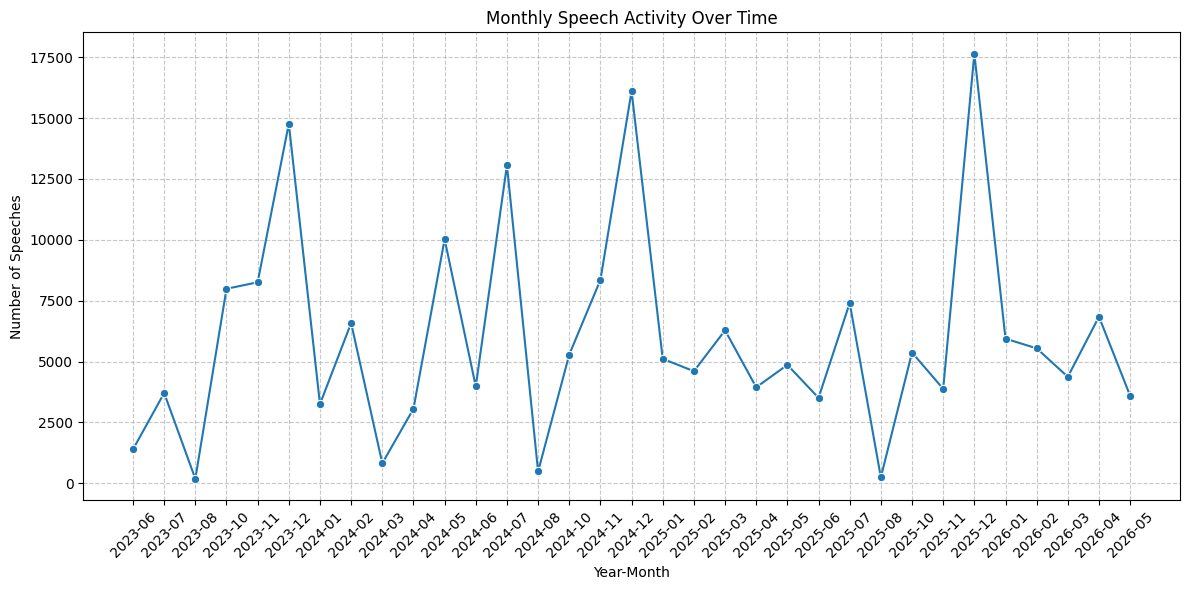

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert PySpark DataFrame to Pandas DataFrame for visualization
monthly_activity_pd = monthly_activity.toPandas()

# Create a combined 'Year-Month' column for better plotting
monthly_activity_pd['YM'] = monthly_activity_pd['year'].astype(str) + '-' + monthly_activity_pd['month'].astype(str).str.zfill(2)

# Sort by 'YM' to ensure correct chronological order
monthly_activity_pd = monthly_activity_pd.sort_values(by='YM')

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_activity_pd, x='YM', y='speech_count', marker='o')
plt.title('Monthly Speech Activity Over Time')
plt.xlabel('Year-Month')
plt.ylabel('Number of Speeches')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()